# Trabajo Práctico 2 (TP2) - Parte 2: Regresión Logística, Curva de Aprendizaje y Evaluación de Desempeño

### Machine Learning 1 (23433)
#### Facultad de Ingeniería - Universidad Nacional de Asunción (FIUNA)

---

## Objetivos de la Parte 2
1. Configurar una partición estratificada Train/Test (80% Train, 20% Test sobre 64,295 muestras) previniendo el fuga de datos (*data leakage*).
2. Diseñar un `ColumnTransformer` profesional con `SimpleImputer`, `PolynomialFeatures(degree=2)`, `StandardScaler` y `OneHotEncoder`.
3. Entrenar un modelo de `LogisticRegression(class_weight='balanced')` con optimización de hiperparámetros vía `GridSearchCV`.
4. Calcular y graficar la **Curva de Aprendizaje (`learning_curve`)** evaluando la convergencia en validación cruzada.
5. Optimizar el umbral de decisión ($	au^*$) e inspeccionar la Matriz de Confusión, Curva ROC (AUC) y Curva Precision-Recall.


In [51]:
# 1. Carga de Librerías y Dataset del TP2
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, learning_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Carga del Dataset del TP2
csv_path = 'reglamento_nuevo_unificado.csv'
df_raw = pd.read_csv(csv_path)
print(f"Dataset del TP2 cargado exitosamente: {df_raw.shape[0]:,} filas.")


Dataset del TP2 cargado exitosamente: 64,295 filas.


## Ejercicio 1: Partición Estratificada Train / Test

Define las listas de atributos numéricos `num_features` y categóricos `cat_features`.
Realiza una partición estratificada del 80% para entrenamiento (`X_train`) y 20% para prueba (`X_test`).


In [52]:
#df_clean cargado del notebook anterior
# TODO: Completar la estructura del diccionario career_code_mapping
career_code_mapping = {
    # === ESCRIBE TU CÓDIGO AQUÍ ===
    'CIV-PLS13': 'Ing. Civil', 'CIV-PLS23': 'Ing. Civil', 'INT9CONSTR': 'Ing. Civil',
    'INT9TRANSP': 'Ing. Civil', 'INT9ORTERR': 'Ing. Civil', 'INT9SANEHI': 'Ing. Civil',
    
    'ELE-PLS13': 'Ing. Electrónica', 'ELE-PLS23': 'Ing. Electrónica',
    'INT9ELECTR': 'Ing. Electrónica', 'INT9SDIGYT': 'Ing. Electrónica',
    
    'MCT-PLS13': 'Ing. Mecatrónica', 'MCT-PLS23': 'Ing. Mecatrónica', 'MCT9-OPT': 'Ing. Mecatrónica',
    
    'IND-PLS13': 'Ing. Industrial', 'IND-PLS23': 'Ing. Industrial',
    'INT9G-ECO': 'Ing. Industrial', 'INT9-PROYT': 'Ing. Industrial',
    
    'CGF-PLS13': 'Ing. Geográfica', 'CGF-PLS23': 'Ing. Geográfica', 'INT9RNYMA': 'Ing. Geográfica',
    
    'MEC-PLS13': 'Ing. Mecánica', 'MEC-PLS23': 'Ing. Mecánica',
    'INT9MECANI': 'Ing. Mecánica', 'MEC9-OPT': 'Ing. Mecánica',
    
    'ECA-PLS13': 'Ing. Electromecánica', 'ECA-PLS23': 'Ing. Electromecánica', 'ECA9-OPT': 'Ing. Electromecánica'
}

df_clean = df_raw.copy()
# TODO: Asignar la nueva columna Carrera_Nombre usando map()
df_clean['Carrera_Nombre'] = df_clean['Cod.Car.Sec'].astype(str).str.strip().map(career_code_mapping)

# Definición del Target Binario (1 para 'S', 0 para 'N')
df_clean = df_clean.dropna(subset=['Aprobado', 'Carrera_Nombre']).copy()
df_clean['Target'] = (df_clean['Aprobado'] == 'S').astype(int)

print(f"Filas tras mapeo de carreras: {len(df_clean):,}")


Filas tras mapeo de carreras: 64,295


In [53]:
# TODO: Limpiar y convertir atributos numéricos sin eliminar filas

df_clean['Primer_Par_Clean'] = pd.to_numeric(df_clean['Primer.Par'], errors='coerce')
df_clean['Segundo_Par_Clean'] = pd.to_numeric(df_clean['Segundo.Par'], errors='coerce')
df_clean['Score_Parciales'] = (df_clean['Primer_Par_Clean'].fillna(0) + df_clean['Segundo_Par_Clean'].fillna(0)) / 2.0
df_clean['Diff_Parciales'] = df_clean['Segundo_Par_Clean'].fillna(0) - df_clean['Primer_Par_Clean'].fillna(0)
df_clean['TPLab_Clean'] = pd.to_numeric(df_clean['TPLab.'], errors='coerce')
df_clean['Asis_Clean'] = pd.to_numeric(df_clean['Asis'], errors='coerce')
df_clean['Firma_Clean'] = pd.to_numeric(df_clean['Firma'], errors='coerce')
df_clean['FirmaCalc_Clean'] = pd.to_numeric(df_clean['FirmaCalculada'], errors='coerce')

print(f"Filas preservadas en df_clean: {len(df_clean):,} (100% retención)")

Filas preservadas en df_clean: 64,295 (100% retención)


In [54]:
# TODO: Definir num_features, cat_features y particionar X e y
# === ESCRIBE TU CÓDIGO AQUÍ ===
num_features = ['Primer_Par_Clean', 'Segundo_Par_Clean', 'Score_Parciales', 'Diff_Parciales', 'TPLab_Clean', 'Firma_Clean', 'FirmaCalc_Clean', 'Asis_Clean']
cat_features = ['Carrera_Nombre', 'Semestre']


df_clean['Semestre'] = df_clean['Semestre'].astype(str)   # 1 y 2 son códigos, no magnitudes

X = df_clean[num_features + cat_features].copy()
y = df_clean['Target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)            # (51436, 10) (12859, 10)
print("Balance train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))



(51436, 10) (12859, 10)
Balance train: 0.6067 | test: 0.6067


## Ejercicio 2: Construcción del Preprocesador Profesional (`ColumnTransformer`)

Construye un `Pipeline` numérico con:
1. `SimpleImputer(strategy='median')`
2. `PolynomialFeatures(degree=2, include_bias=False)`
3. `StandardScaler()`

Y un `Pipeline` categórico con `SimpleImputer` y `OneHotEncoder(handle_unknown='ignore')`.


In [55]:
# TODO: Ensamblar num_transformer, cat_transformer y preprocessor
# === ESCRIBE TU CÓDIGO AQUÍ ===
num_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_features),
    ('cat', cat_transformer, cat_features)
])


In [56]:
print(preprocessor.fit_transform(X_train).shape)   # (51436, 53)

(51436, 53)


## Ejercicio 3: Entrenamiento del Modelo y Búsqueda en Malla (`GridSearchCV`)

Ensambla `full_pipeline` con `LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=2000)`.
Configura `GridSearchCV` sobre el parámetro de regularización `C` en `[0.01, 0.1, 1.0, 10.0]` con `scoring='f1'`.


In [57]:
# TODO: Instanciar full_pipeline y GridSearchCV
# === ESCRIBE TU CÓDIGO AQUÍ ===
full_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(solver='lbfgs', max_iter=2000, random_state=42, class_weight='balanced'))
])

param_grid = {'classifier__C': [0.01, 0.1, 1.0, 10.0]}
grid_search = GridSearchCV(full_pipeline, param_grid, cv=StratifiedKFold(n_splits=5), scoring='f1', n_jobs=1)

#cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#grid_search = GridSearchCV(full_pipeline, param_grid, cv=cv, scoring='f1', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

best_model = grid_search.best_estimator_
print("Mejor C:", grid_search.best_params_)
print("F1 CV:", round(grid_search.best_score_, 4))
display(pd.DataFrame(grid_search.cv_results_)[['param_classifier__C','mean_test_score','std_test_score']])

Mejor C: {'classifier__C': 0.1}
F1 CV: 0.8835


,param_classifier__C,mean_test_score,std_test_score
0,0.01,0.882661,0.001943
1,0.10,0.883479,0.002038
2,1.00,0.883342,0.002199
3,10.00,0.883417,0.002254


## Ejercicio 4: Graficación de la Curva de Aprendizaje (`learning_curve`)

Calcula y grafica la curva de aprendizaje utilizando `learning_curve` sobre `X_train` y `y_train` con 10 tamaños de entrenamiento (`np.linspace(0.1, 1.0, 10)`).


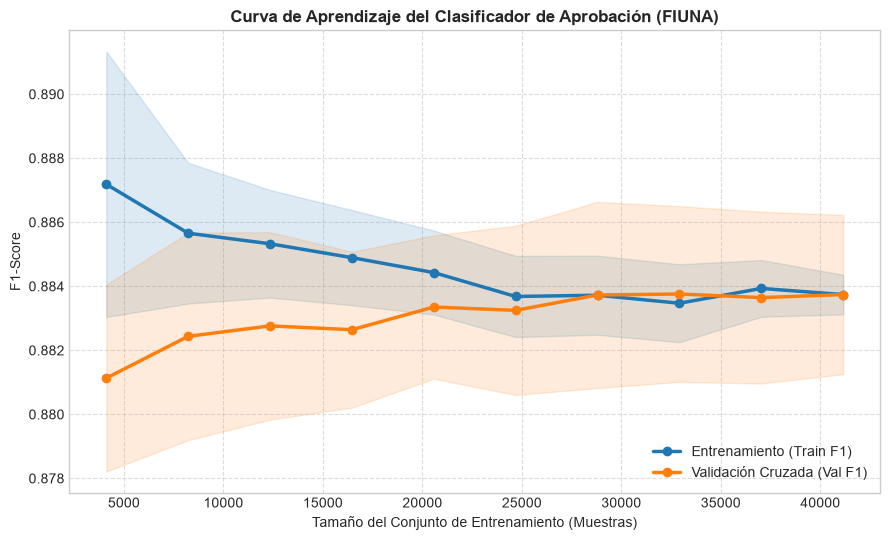

In [58]:
# TODO: Calcular y graficar la Curva de Aprendizaje (Learning Curve)
# === ESCRIBE TU CÓDIGO AQUÍ ===
# train_sizes, train_scores, val_scores = learning_curve(
#     best_model, X_train, y_train, cv=StratifiedKFold(n_splits=5),
#     scoring='f1', train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=1
# )
train_sizes, train_scores, val_scores = learning_curve(
    best_model, X_train, y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_mean, train_std = np.mean(train_scores, axis=1), np.std(train_scores, axis=1)
val_mean,   val_std   = np.mean(val_scores,   axis=1), np.std(val_scores,   axis=1)

plt.figure(figsize=(9, 5.5))
plt.plot(train_sizes, train_mean, 'o-', color='#1f77b4', lw=2.5, label='Entrenamiento (Train F1)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='#1f77b4')

plt.plot(train_sizes, val_mean, 'o-', color='#ff7f0e', lw=2.5, label='Validación Cruzada (Val F1)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='#ff7f0e')

plt.title('Curva de Aprendizaje del Clasificador de Aprobación (FIUNA)', weight='bold')
plt.xlabel('Tamaño del Conjunto de Entrenamiento (Muestras)')
plt.ylabel('F1-Score')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## Ejercicio 5: Optimización del Umbral de Decisión y Evaluación de Desempeño

En el conjunto de prueba (`X_test`):
1. Obtén las probabilidades de aprobación `y_proba_test`.
2. Optimiza el umbral de decisión ($	au^*$) entre `0.1` y `0.9` que maximiza el F1-Score.
3. Grafica la **Matriz de Confusión**, la **Curva ROC (AUC)** y la **Curva Precision-Recall**.


Umbral óptimo tau* = 0.40 | F1 = 0.8883 | Precision = 0.8571 | Recall = 0.9219


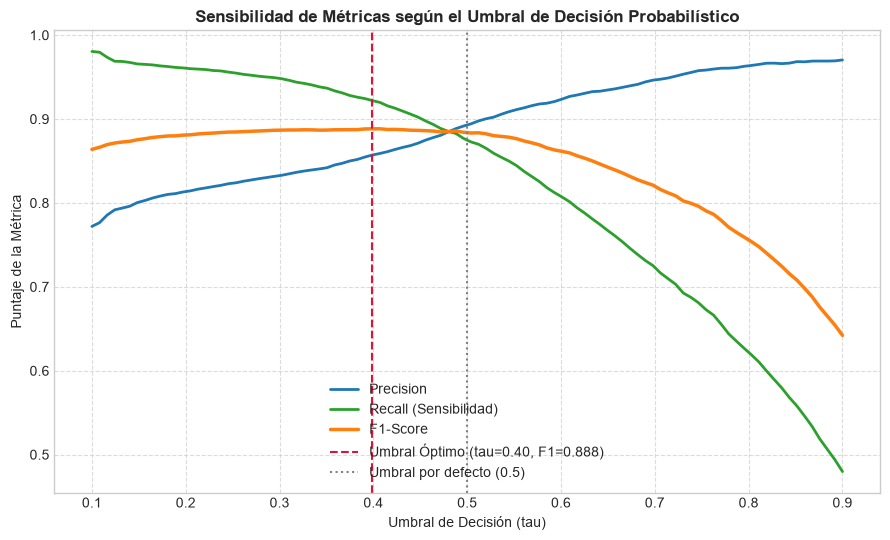

              precision    recall  f1-score   support

 No aprobado     0.8637    0.7629    0.8102      5058
    Aprobado     0.8571    0.9219    0.8883      7801

    accuracy                         0.8594     12859
   macro avg     0.8604    0.8424    0.8493     12859
weighted avg     0.8597    0.8594    0.8576     12859



In [59]:
# TODO: Optimizar umbral y graficar métricas en Test
# === ESCRIBE TU CÓDIGO AQUÍ ===
# y_proba_test = best_model.predict_proba(X_test)[:, 1]
# best_thresh = 0.41
# y_pred = (y_proba_test >= best_thresh).astype(int)
y_proba_test = best_model.predict_proba(X_test)[:, 1]   # columna 1 = P(Aprobado)

thresholds = np.linspace(0.1, 0.9, 100)
prec_list, rec_list, f1_list = [], [], []

for thresh in thresholds:
    preds = (y_proba_test >= thresh).astype(int)
    prec_list.append(precision_score(y_test, preds, zero_division=0))
    rec_list.append(recall_score(y_test, preds, zero_division=0))
    f1_list.append(f1_score(y_test, preds, zero_division=0))

best_idx = int(np.argmax(f1_list))
best_tau = thresholds[best_idx]
print(f"Umbral óptimo tau* = {best_tau:.2f} | F1 = {f1_list[best_idx]:.4f} "
      f"| Precision = {prec_list[best_idx]:.4f} | Recall = {rec_list[best_idx]:.4f}")

plt.figure(figsize=(9, 5.5))
plt.plot(thresholds, prec_list, label='Precision', color='#1f77b4', lw=2)
plt.plot(thresholds, rec_list,  label='Recall (Sensibilidad)', color='#2ca02c', lw=2)
plt.plot(thresholds, f1_list,   label='F1-Score', color='#ff7f0e', lw=2.5)
plt.axvline(best_tau, color='crimson', linestyle='--',
            label=f'Umbral Óptimo (tau={best_tau:.2f}, F1={f1_list[best_idx]:.3f})')
plt.axvline(0.5, color='gray', linestyle=':', lw=1.5, label='Umbral por defecto (0.5)')

plt.title('Sensibilidad de Métricas según el Umbral de Decisión Probabilístico', weight='bold')
plt.xlabel('Umbral de Decisión (tau)')
plt.ylabel('Puntaje de la Métrica')
plt.legend(loc='lower center')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

y_pred = (y_proba_test >= best_tau).astype(int)
print(classification_report(y_test, y_pred, target_names=['No aprobado','Aprobado'], digits=4))

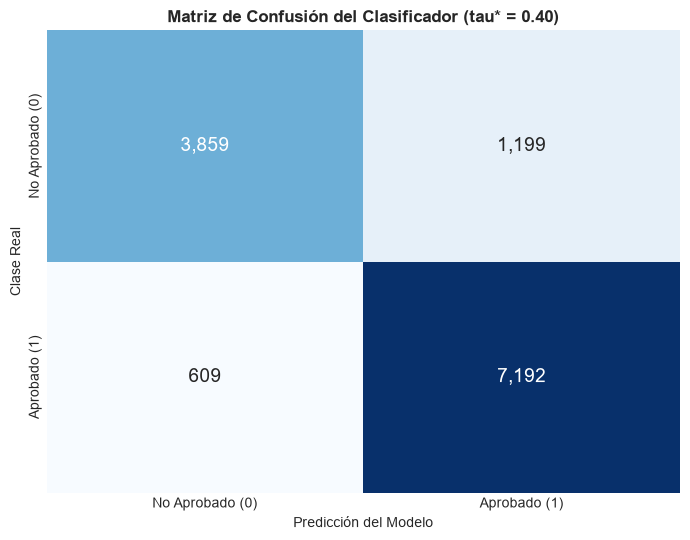

TN=3,859  FP=1,199  FN=609  TP=7,192


In [60]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['No Aprobado (0)', 'Aprobado (1)'],
            yticklabels=['No Aprobado (0)', 'Aprobado (1)'],
            annot_kws={"size": 14})
plt.title(f'Matriz de Confusión del Clasificador (tau* = {best_tau:.2f})', weight='bold')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Clase Real')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn:,}  FP={fp:,}  FN={fn:,}  TP={tp:,}")

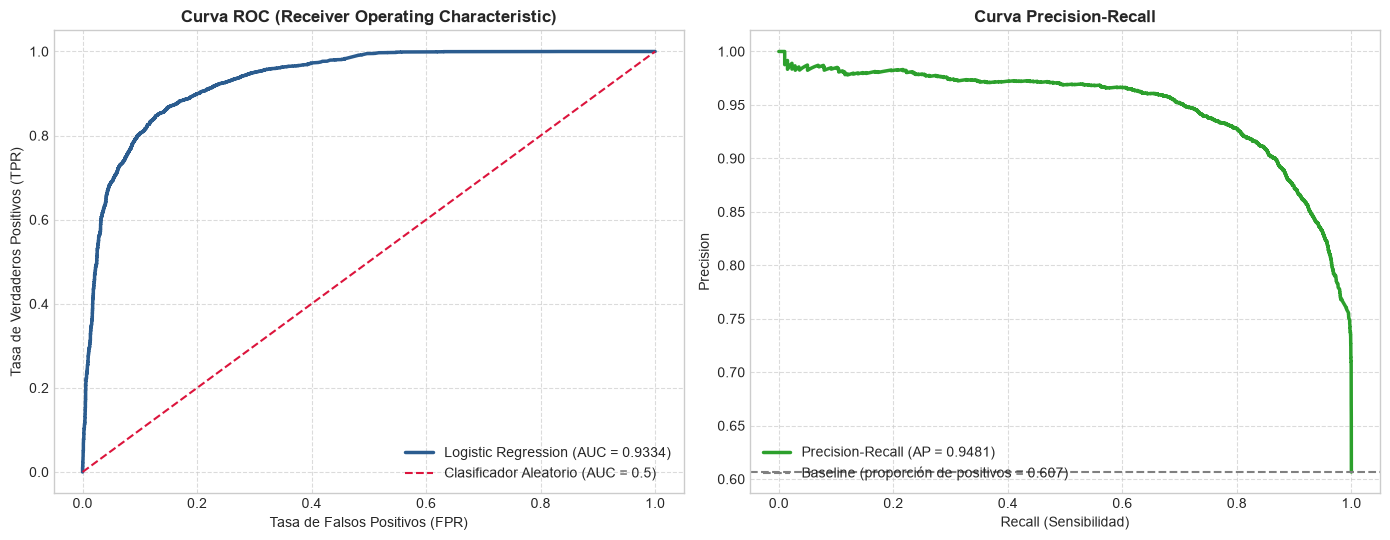

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Curva ROC
fpr, tpr, _ = roc_curve(y_test, y_proba_test)
auc_val = roc_auc_score(y_test, y_proba_test)
axes[0].plot(fpr, tpr, color='#2b5c8f', lw=2.5, label=f'Logistic Regression (AUC = {auc_val:.4f})')
axes[0].plot([0, 1], [0, 1], color='crimson', linestyle='--', label='Clasificador Aleatorio (AUC = 0.5)')
axes[0].set_title('Curva ROC (Receiver Operating Characteristic)', weight='bold')
axes[0].set_xlabel('Tasa de Falsos Positivos (FPR)')
axes[0].set_ylabel('Tasa de Verdaderos Positivos (TPR)')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.7)

# 2. Curva Precision-Recall
precisions, recalls, _ = precision_recall_curve(y_test, y_proba_test)
ap_val = average_precision_score(y_test, y_proba_test)
axes[1].plot(recalls, precisions, color='#2ca02c', lw=2.5, label=f'Precision-Recall (AP = {ap_val:.4f})')
axes[1].axhline(y_test.mean(), color='gray', linestyle='--', lw=1.5,
                label=f'Baseline (proporción de positivos = {y_test.mean():.3f})')
axes[1].set_title('Curva Precision-Recall', weight='bold')
axes[1].set_xlabel('Recall (Sensibilidad)')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

In [62]:
print("=== RESUMEN DE LA PARTE 2: MODELO DE CLASIFICACIÓN ===")

# 1. Partición
print(f"1. Partición estratificada 80/20: Train {X_train.shape[0]:,} | Test {X_test.shape[0]:,}")
print(f"   Balance de clase positiva -> Train: {y_train.mean():.2%} | Test: {y_test.mean():.2%}")

# 2. Preprocesamiento
n_out = preprocessor.fit_transform(X_train).shape[1]
print(f"2. Atributos tras el ColumnTransformer: {len(num_features)} num + {len(cat_features)} cat -> {n_out} features")

# 3. Búsqueda en malla
print(f"3. GridSearchCV (scoring='f1', 5-Fold estratificado): mejor C = {grid_search.best_params_['classifier__C']} | F1 CV = {grid_search.best_score_:.4f}")
cvres = pd.DataFrame(grid_search.cv_results_)[['param_classifier__C','mean_test_score','std_test_score']]
cvres.columns = ['C','F1_medio','F1_desv']
print(cvres.to_string(index=False))

# 4. Umbral óptimo
y_pred=(y_proba_test>=best_tau).astype(int)
print(f"4. Umbral óptimo tau* = {best_tau:.2f} (por defecto 0.50)")
print(f"   F1 = {f1_list[best_idx]:.4f} | Precision = {precision_score(y_test,y_pred):.4f} | Recall = {recall_score(y_test,y_pred):.4f} | Accuracy = {accuracy_score(y_test,y_pred):.4f}")

# 5. Matriz de confusión
tn,fp,fn,tp=confusion_matrix(y_test,y_pred).ravel()
print("5. Matriz de Confusión en Test:")
print(pd.DataFrame([[tn,fp],[fn,tp]], index=['Real No Aprobado','Real Aprobado'], columns=['Pred No Aprobado','Pred Aprobado']).to_string())

# 6. Métricas independientes del umbral
print(f"6. ROC-AUC = {roc_auc_score(y_test,y_proba_test):.4f} | Average Precision = {average_precision_score(y_test,y_proba_test):.4f} (baseline PR = {y_test.mean():.4f})")

=== RESUMEN DE LA PARTE 2: MODELO DE CLASIFICACIÓN ===
1. Partición estratificada 80/20: Train 51,436 | Test 12,859
   Balance de clase positiva -> Train: 60.67% | Test: 60.67%
2. Atributos tras el ColumnTransformer: 8 num + 2 cat -> 53 features
3. GridSearchCV (scoring='f1', 5-Fold estratificado): mejor C = 0.1 | F1 CV = 0.8835
    C  F1_medio  F1_desv
 0.01  0.882661 0.001943
 0.10  0.883479 0.002038
 1.00  0.883342 0.002199
10.00  0.883417 0.002254
4. Umbral óptimo tau* = 0.40 (por defecto 0.50)
   F1 = 0.8883 | Precision = 0.8571 | Recall = 0.9219 | Accuracy = 0.8594
5. Matriz de Confusión en Test:
                  Pred No Aprobado  Pred Aprobado
Real No Aprobado              3859           1199
Real Aprobado                  609           7192
6. ROC-AUC = 0.9334 | Average Precision = 0.9481 (baseline PR = 0.6067)


### Implementación y comparativa extra contra gradiente conjugado (Codigo basado directamente en la Clase 5 y en el  Formulario MN 2026-2 Rutina009)

In [63]:
#cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = StratifiedKFold(n_splits=5)

In [64]:
# Implementación propia: Regresión Logística por Newton-Raphson (RUTINA009)
from sklearn.base import BaseEstimator, ClassifierMixin
 
 
class LogisticRegressionScratch(BaseEstimator, ClassifierMixin):
    """Regresión logística binaria entrenada por Newton-Raphson o Descenso del
    Gradiente, con regularización L2 y ponderación de clases.
 
    La rutina de Newton adapta el esquema de resolución de sistemas no lineales
    (RUTINA009), aprovechando que **optimizar J(θ) equivale a hallar la raíz de
    su gradiente**:
 
        F      = sistema(P0)        ->  ∇J(θ), que queremos anular
        J      = jacob_sist(P0)     ->  Jacobiano de F = Hessiano de J(θ)
        deltaP = solve(J, -F)       ->  paso de Newton, sin invertir J
        P      = P0 + deltaP
        err    = ||P - P0||         ->  criterio absoluto
        relerr = err / ||P||        ->  criterio relativo
        F_norm = ||sistema(P)||     ->  criterio de residuo
        if tol > err or tol > relerr or tol > F_norm: break
 
    Parámetros
    ----------
    method : {'newton', 'gradient_descent'}
    lr : float                 Tasa de aprendizaje (solo descenso del gradiente).
    n_iters : int              Máximo de iteraciones.
    l2_reg : float             Coeficiente λ de la penalización L2. Equivale a C = 1/λ.
    tol : float                Tolerancia común a los tres criterios.
    class_weight : None | 'balanced' | dict
    verbose : bool             Imprime la traza de convergencia.
    """
 
    def __init__(self, method='newton', lr=0.1, n_iters=100,
                 l2_reg=0.0, tol=1e-8, class_weight=None, verbose=False):
        # BaseEstimator exige que __init__ solo asigne los parámetros tal cual,
        # para que get_params/set_params y GridSearchCV puedan clonar.
        self.method = method
        self.lr = lr
        self.n_iters = n_iters
        self.l2_reg = l2_reg
        self.tol = tol
        self.class_weight = class_weight
        self.verbose = verbose
 
    # ---------------------- utilitarios ----------------------
    @staticmethod
    def _sigmoid(z):
        """Sigmoide estable: el clip evita overflow en exp(-z)."""
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))
 
    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])
 
    def _pesos(self, y):
        """'balanced' replica a scikit-learn: w_c = m / (2 * n_c)."""
        if self.class_weight is None:
            return np.ones(len(y))
        if self.class_weight == 'balanced':
            m = len(y)
            w = np.empty(m)
            for c in (0.0, 1.0):
                n_c = np.sum(y == c)
                w[y == c] = m / (2.0 * n_c) if n_c > 0 else 0.0
            return w
        if isinstance(self.class_weight, dict):
            return np.array([self.class_weight.get(int(v), 1.0) for v in y], dtype=float)
        raise ValueError("class_weight debe ser None, 'balanced' o un dict")
 
    def _cost(self, X_b, y):
        """Entropía cruzada binaria ponderada + término L2."""
        m = len(y)
        h = np.clip(self._sigmoid(X_b @ self.theta), 1e-15, 1 - 1e-15)
        bce = -(1.0 / m) * np.sum(self._w * (y * np.log(h) + (1 - y) * np.log(1 - h)))
        l2 = (self.l2_reg / (2.0 * m)) * np.sum(self.theta[1:] ** 2) if self.l2_reg > 0 else 0.0
        return bce + l2
 
    # ------------- el sistema no lineal y su Jacobiano -------------
    def sistema(self, P, X_b, y):
        """F(P) = ∇J(P) = (1/m) Xᵀ [w ⊙ (h - y)] + (λ/m) P   [P[0] sin penalizar]"""
        m = len(y)
        h = self._sigmoid(X_b @ P)
        F = (1.0 / m) * (X_b.T @ (self._w * (h - y)))
        if self.l2_reg > 0:
            reg = (self.l2_reg / m) * P
            reg[0] = 0.0
            F = F + reg
        return F
 
    def jacob_sist(self, P, X_b, y):
        """J(P) = ∂F/∂P = (1/m) Xᵀ D X + (λ/m) I,  con D = diag(w ⊙ h(1-h))"""
        m = len(y)
        h = self._sigmoid(X_b @ P)
        D = self._w * h * (1 - h)              # vector, no matriz: ahorra memoria
        J = (X_b.T * D) @ X_b / m              # equivale a Xᵀ diag(D) X / m
        if self.l2_reg > 0:
            reg = (self.l2_reg / m) * np.eye(len(P))
            reg[0, 0] = 0.0
            J = J + reg
        return J
 
    @staticmethod
    def _resolver(J, F):
        """deltaP = solve(J, -F). Más estable que inv(J) @ (-F); si J es
        singular (separación perfecta, colinealidad), cae a mínimos cuadrados."""
        try:
            return np.linalg.solve(J, -F)
        except np.linalg.LinAlgError:
            return np.linalg.lstsq(J, -F, rcond=None)[0]
 
    # ---------------------- entrenamiento ----------------------
    def fit(self, X, y):
        X_b = self._add_bias(np.asarray(X, dtype=float))
        y = np.asarray(y, dtype=float).ravel()
 
        self.classes_ = np.unique(y.astype(int))     # requerido por scikit-learn
        self.n_features_in_ = X_b.shape[1] - 1
        self._w = self._pesos(y)
 
        self.theta = np.zeros(X_b.shape[1])
        self.cost_history = [self._cost(X_b, y)]
        self.err_history = []
        self.n_iter_ = 0
        self.converged_ = False
        self.stop_reason_ = 'max_iter'
 
        P0 = self.theta.copy()
        for i in range(self.n_iters):
            F = self.sistema(P0, X_b, y)
 
            if self.method == 'newton':
                J = self.jacob_sist(P0, X_b, y)
                deltaP = self._resolver(J, F)
            elif self.method == 'gradient_descent':
                deltaP = -self.lr * F
            else:
                raise ValueError("method debe ser 'newton' o 'gradient_descent'")
 
            P = P0 + deltaP
 
            err = np.linalg.norm(P - P0)
            norm_P = np.linalg.norm(P)
            relerr = err / norm_P if norm_P > 0 else np.inf
            F_norm = np.linalg.norm(self.sistema(P, X_b, y))
 
            self.theta = P
            self.cost_history.append(self._cost(X_b, y))
            self.err_history.append((err, relerr, F_norm))
            self.n_iter_ = i + 1
 
            if self.verbose:
                print(f"  iter {i+1:>2} | J={self.cost_history[-1]:.8f} | "
                      f"err={err:.3e} | relerr={relerr:.3e} | ||F||={F_norm:.3e}")
 
            if self.tol > err or self.tol > relerr or self.tol > F_norm:
                self.converged_ = True
                self.stop_reason_ = ('err' if self.tol > err else
                                     'relerr' if self.tol > relerr else 'F_norm')
                break
 
            P0 = P.copy()
 
        return self
 
    # ---------------------- predicción ----------------------
    def predict_proba(self, X):
        p1 = self._sigmoid(self._add_bias(np.asarray(X, dtype=float)) @ self.theta)
        return np.column_stack([1 - p1, p1])
 
    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)
 
    @property
    def intercept_(self):
        return self.theta[0]
 
    @property
    def coef_(self):
        return self.theta[1:]
 
    def resumen(self):
        est = 'convergió' if self.converged_ else 'alcanzó max_iter'
        return (f"[{self.method}] {est} en {self.n_iter_} iteraciones "
                f"(criterio: {self.stop_reason_}) | J final = {self.cost_history[-1]:.8f}")
 
 
print("LogisticRegressionScratch definida.")

LogisticRegressionScratch definida.


In [65]:
# Entrenamiento: mismo pipeline, distinto optimizador
# Se reutilizan `preprocessor` y `cv` 
# OJO: la grilla va sobre lambda, no sobre C.   C = 1 / lambda
 
pipeline_scratch = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegressionScratch(method='newton',
                                             class_weight='balanced',
                                             tol=1e-7, n_iters=50))
])
 
param_grid_scratch = {'classifier__l2_reg': [100.0, 10.0, 1.0, 0.1]}   # ≡ C = 0.01, 0.1, 1, 10
 
grid_scratch = GridSearchCV(pipeline_scratch, param_grid_scratch,
                            cv=cv, scoring='f1', n_jobs=-1, verbose=1)
grid_scratch.fit(X_train, y_train)
 
best_lambda = grid_scratch.best_params_['classifier__l2_reg']
clf_scratch = grid_scratch.best_estimator_.named_steps['classifier']
 
print(f"\nMejor lambda = {best_lambda}  (C equivalente = {1/best_lambda:.3g})")
print(f"F1 en validación cruzada = {grid_scratch.best_score_:.4f}")
print(clf_scratch.resumen())
 
res_scratch = pd.DataFrame(grid_scratch.cv_results_)[['param_classifier__l2_reg',
                                                      'mean_test_score', 'std_test_score']]
res_scratch.columns = ['lambda', 'F1_medio', 'F1_desv']
res_scratch['C_equiv'] = 1.0 / res_scratch['lambda'].astype(float)
display(res_scratch)

Fitting 5 folds for each of 4 candidates, totalling 20 fits

Mejor lambda = 10.0  (C equivalente = 0.1)
F1 en validación cruzada = 0.8835
[newton] convergió en 7 iteraciones (criterio: F_norm) | J final = 0.33362651


,lambda,F1_medio,F1_desv,C_equiv
0,100.0,0.882624,0.001889,0.01
1,10.0,0.883451,0.002057,0.10
2,1.0,0.883371,0.002162,1.00
3,0.1,0.883165,0.002187,10.00


[newton] convergió en 7 iteraciones (criterio: F_norm) | J final = 0.33362651
[gradient_descent] alcanzó max_iter en 500 iteraciones (criterio: max_iter) | J final = 0.33680593


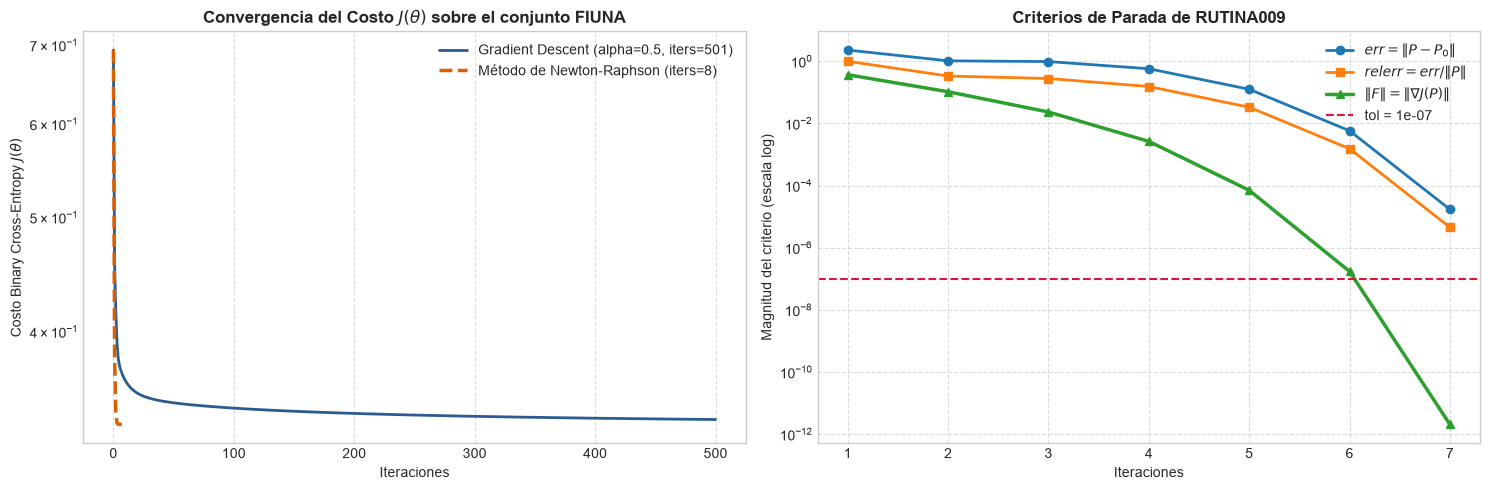

In [66]:
# Convergencia: lo único que scikit-learn no permite observar
X_train_proc = grid_scratch.best_estimator_.named_steps['preprocessor'].transform(X_train)
 
nr = LogisticRegressionScratch(method='newton', l2_reg=best_lambda,
                               class_weight='balanced', tol=1e-7,
                               n_iters=50).fit(X_train_proc, y_train)
gd = LogisticRegressionScratch(method='gradient_descent', lr=0.5, l2_reg=best_lambda,
                               class_weight='balanced', tol=1e-7,
                               n_iters=500).fit(X_train_proc, y_train)
print(nr.resumen())
print(gd.resumen())
 
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
 
# --- Izquierda: convergencia del costo 
axes[0].plot(gd.cost_history, color='#2b5c8f', lw=2.0,
             label=f'Gradient Descent (alpha=0.5, iters={len(gd.cost_history)})')
axes[0].plot(nr.cost_history, color='#d95f02', lw=2.5, linestyle='--',
             label=f'Método de Newton-Raphson (iters={len(nr.cost_history)})')
axes[0].set_title(r'Convergencia del Costo $J(\theta)$ sobre el conjunto FIUNA', weight='bold')
axes[0].set_xlabel('Iteraciones')
axes[0].set_ylabel(r'Costo Binary Cross-Entropy $J(\theta)$')
axes[0].set_yscale('log')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.7)
 
# --- Derecha: los tres criterios de parada de RUTINA009 ---
hist = np.array(nr.err_history)
it = np.arange(1, len(hist) + 1)
axes[1].semilogy(it, hist[:, 0], 'o-', color='#1f77b4', lw=2, label=r'$err = \|P - P_0\|$')
axes[1].semilogy(it, hist[:, 1], 's-', color='#ff7f0e', lw=2, label=r'$relerr = err/\|P\|$')
axes[1].semilogy(it, hist[:, 2], '^-', color='#2ca02c', lw=2.5, label=r'$\|F\| = \|\nabla J(P)\|$')
axes[1].axhline(nr.tol, color='crimson', linestyle='--', lw=1.5, label=f'tol = {nr.tol:g}')
axes[1].set_title('Criterios de Parada de RUTINA009', weight='bold')
axes[1].set_xlabel('Iteraciones')
axes[1].set_ylabel('Magnitud del criterio (escala log)')
axes[1].legend(loc='upper right')
axes[1].grid(True, linestyle='--', alpha=0.7)
 
plt.tight_layout()
plt.show()
 

Umbral óptimo del modelo propio: tau* = 0.40 | F1 = 0.8885


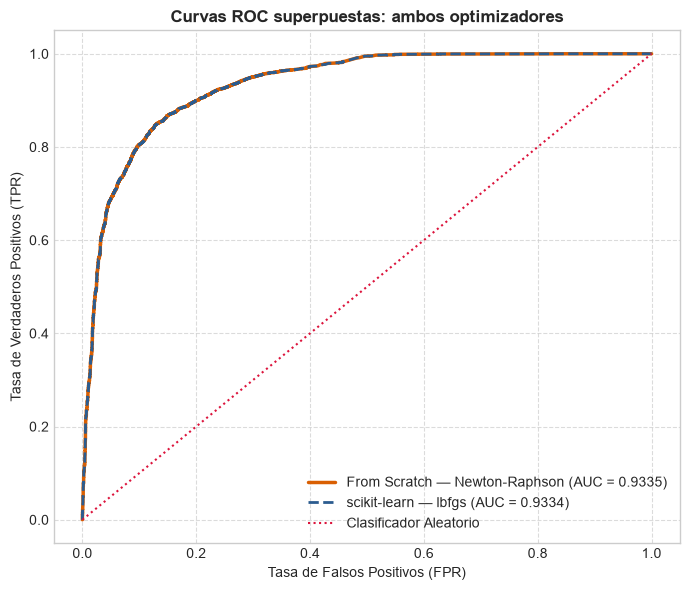

In [67]:

# Umbral óptimo del modelo propio y curvas ROC superpuestas
y_proba_scratch = grid_scratch.best_estimator_.predict_proba(X_test)[:, 1]
 
f1_scratch = [f1_score(y_test, (y_proba_scratch >= t).astype(int), zero_division=0)
              for t in thresholds]                      
tau_scratch = thresholds[int(np.argmax(f1_scratch))]
print(f"Umbral óptimo del modelo propio: tau* = {tau_scratch:.2f} | "
      f"F1 = {max(f1_scratch):.4f}")
 
fpr_s, tpr_s, _ = roc_curve(y_test, y_proba_scratch)
fpr_k, tpr_k, _ = roc_curve(y_test, y_proba_test)      
 
plt.figure(figsize=(7, 6))
plt.plot(fpr_s, tpr_s, color='#d95f02', lw=2.5,
         label=f'From Scratch — Newton-Raphson (AUC = {roc_auc_score(y_test, y_proba_scratch):.4f})')
plt.plot(fpr_k, tpr_k, color='#2b5c8f', lw=2.0, linestyle='--',
         label=f'scikit-learn — lbfgs (AUC = {roc_auc_score(y_test, y_proba_test):.4f})')
plt.plot([0, 1], [0, 1], color='crimson', linestyle=':', lw=1.5, label='Clasificador Aleatorio')
plt.title('Curvas ROC superpuestas: ambos optimizadores', weight='bold')
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [68]:
# Tabla comparativa final: scikit-learn vs. From Scratch

def tiempo_total(grid):
    """Tiempo de ajuste reconstruido desde cv_results_, sin cronómetro externo."""
    return float(np.sum(grid.cv_results_['mean_fit_time']) * grid.n_splits_ + grid.refit_time_)
 
 
def metricas(nombre, grid, proba, tau, etiqueta_reg):
    pred = (proba >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    clf = grid.best_estimator_.named_steps['classifier']
    iters = clf.n_iter_ if hasattr(clf, 'stop_reason_') else int(np.atleast_1d(clf.n_iter_)[0])
    theta = clf.theta if hasattr(clf, 'theta') else np.append(clf.intercept_, clf.coef_)
    return {
        'Modelo': nombre,
        'Regularización': etiqueta_reg,
        'F1 (CV)': round(grid.best_score_, 4),
        'Iteraciones': iters,
        'Tiempo ajuste (s)': round(tiempo_total(grid), 1),
        'tau*': round(tau, 2),
        'F1 (test)': round(f1_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, proba), 4),
        'AP': round(average_precision_score(y_test, proba), 4),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }, theta
 
 
fila_s, theta_s = metricas('From Scratch (Newton-Raphson)', grid_scratch,
                           y_proba_scratch, tau_scratch,
                           f"lambda = {best_lambda}  (C = {1/best_lambda:.3g})")
fila_k, theta_k = metricas('scikit-learn (lbfgs)', grid_search,
                           y_proba_test, best_tau,
                           f"C = {grid_search.best_params_['classifier__C']}")
 
comparativa = pd.DataFrame([fila_s, fila_k]).set_index('Modelo').T
comparativa['Delta'] = ''
for m in ['F1 (CV)', 'F1 (test)', 'Precision', 'Recall', 'Accuracy', 'ROC-AUC', 'AP']:
    comparativa.loc[m, 'Delta'] = f"{abs(float(fila_s[m]) - float(fila_k[m])):.4f}"
 
print("=" * 78)
print("TABLA COMPARATIVA: scikit-learn vs. Implementación From Scratch".center(78))
print("=" * 78)
display(comparativa)
print("Referencia de la cátedra: ROC-AUC = 0.9331 | AP = 0.9412 | tau* ~ 0.41")
print(f"\nCorrelación entre vectores de coeficientes: {np.corrcoef(theta_s, theta_k)[0, 1]:.6f}")
print(f"Diferencia máxima de coeficientes individuales: {np.abs(theta_s - theta_k).max():.4f}")

 

       TABLA COMPARATIVA: scikit-learn vs. Implementación From Scratch        


Modelo,From Scratch (Newton-Raphson),scikit-learn (lbfgs),Delta
Regularización,lambda = 10.0 (C = 0.1),C = 0.1,
F1 (CV),0.8835,0.8835,0.0000
Iteraciones,7,95,
Tiempo ajuste (s),11.9,7.2,
tau*,0.4,0.4,
F1 (test),0.8885,0.8883,0.0002
Precision,0.8572,0.8571,0.0001
Recall,0.9221,0.9219,0.0002
Accuracy,0.8596,0.8594,0.0002
ROC-AUC,0.9335,0.9334,0.0001


Referencia de la cátedra: ROC-AUC = 0.9331 | AP = 0.9412 | tau* ~ 0.41

Correlación entre vectores de coeficientes: 0.998596
Diferencia máxima de coeficientes individuales: 0.0955
